<a href="https://colab.research.google.com/github/shreyashrodge83-create/EE-AIML-SEM-5-/blob/main/ML_OIL_P.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()  # Select transformer_oil_condition_dataset.csv

import io
import pandas as pd

csv_name = next((name for name in uploaded if name.lower().endswith('.csv')), None)
if csv_name is None:
    raise ValueError('Please upload a CSV dataset file.')
df = pd.read_csv(io.BytesIO(uploaded[csv_name]))

print('Dataset shape:', df.shape)
display(df.head())
print('\nColumns:', df.columns.tolist())
print('\nMissing values:\n', df.isnull().sum())

Saving transformer_oil_condition_dataset.csv to transformer_oil_condition_dataset (1).csv
Dataset shape: (600, 14)


,transformer_id,hydrogen_ppm,methane_ppm,ethane_ppm,ethylene_ppm,acetylene_ppm,carbon_monoxide_ppm,carbon_dioxide_ppm,moisture_ppm,acidity_mgKOH_g,dielectric_strength_kV,oil_temperature_C,load_percent,oil_condition
0,TR-0001,72.39,39.31,6.12,15.24,1.47,24.05,241.25,13.10,0.326,49.82,76.57,79.34,Normal
1,TR-0002,39.95,144.90,2.25,24.92,4.18,19.25,125.45,20.75,0.425,53.90,56.40,55.29,Normal
2,TR-0003,155.86,7.97,19.29,14.68,0.54,40.09,211.23,34.16,0.282,49.53,83.26,96.04,Normal
3,TR-0004,20.94,67.20,73.85,38.87,2.02,32.64,167.77,25.63,0.266,47.05,86.11,54.19,Normal
4,TR-0005,15.40,17.52,39.69,9.59,2.55,1.84,220.50,18.96,0.350,47.10,42.73,53.99,Normal



Columns: ['transformer_id', 'hydrogen_ppm', 'methane_ppm', 'ethane_ppm', 'ethylene_ppm', 'acetylene_ppm', 'carbon_monoxide_ppm', 'carbon_dioxide_ppm', 'moisture_ppm', 'acidity_mgKOH_g', 'dielectric_strength_kV', 'oil_temperature_C', 'load_percent', 'oil_condition']

Missing values:
 transformer_id            0
hydrogen_ppm              0
methane_ppm               0
ethane_ppm                0
ethylene_ppm              0
acetylene_ppm             0
carbon_monoxide_ppm       0
carbon_dioxide_ppm        0
moisture_ppm              0
acidity_mgKOH_g           0
dielectric_strength_kV    0
oil_temperature_C         0
load_percent              0
oil_condition             0
dtype: int64


Condition counts:


,Count
Condition,
Normal,500
Warning,99
Critical,1


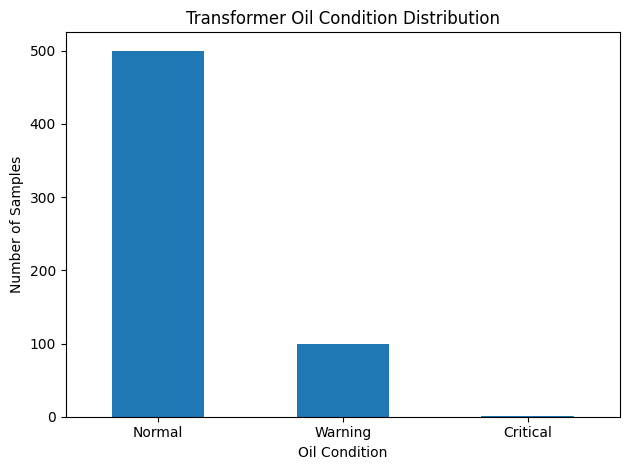

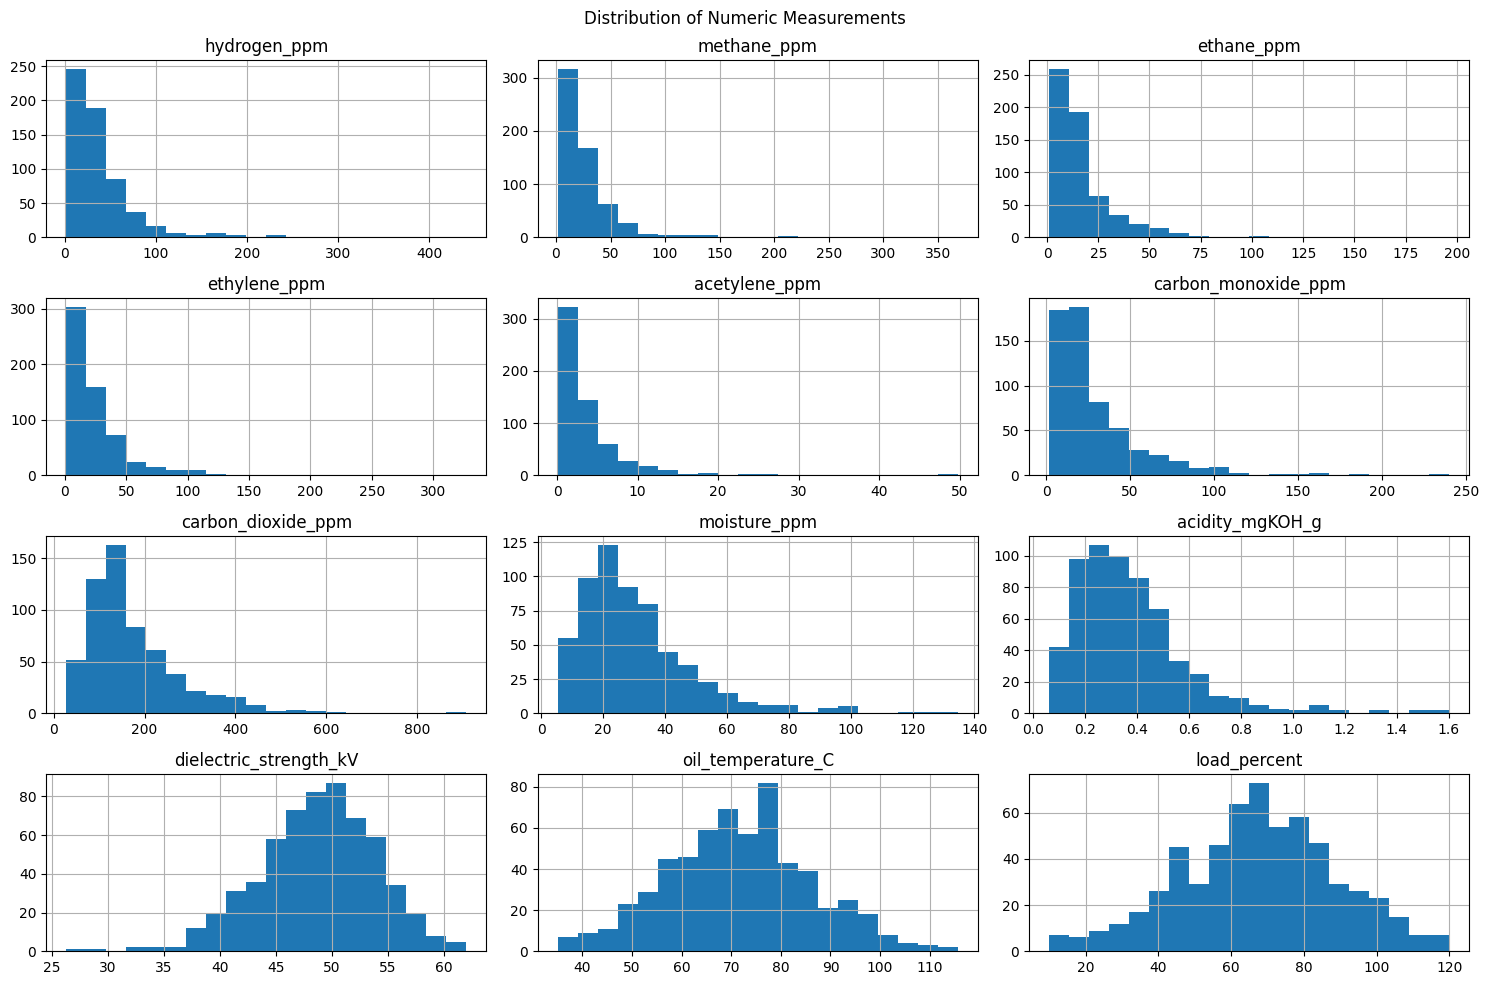

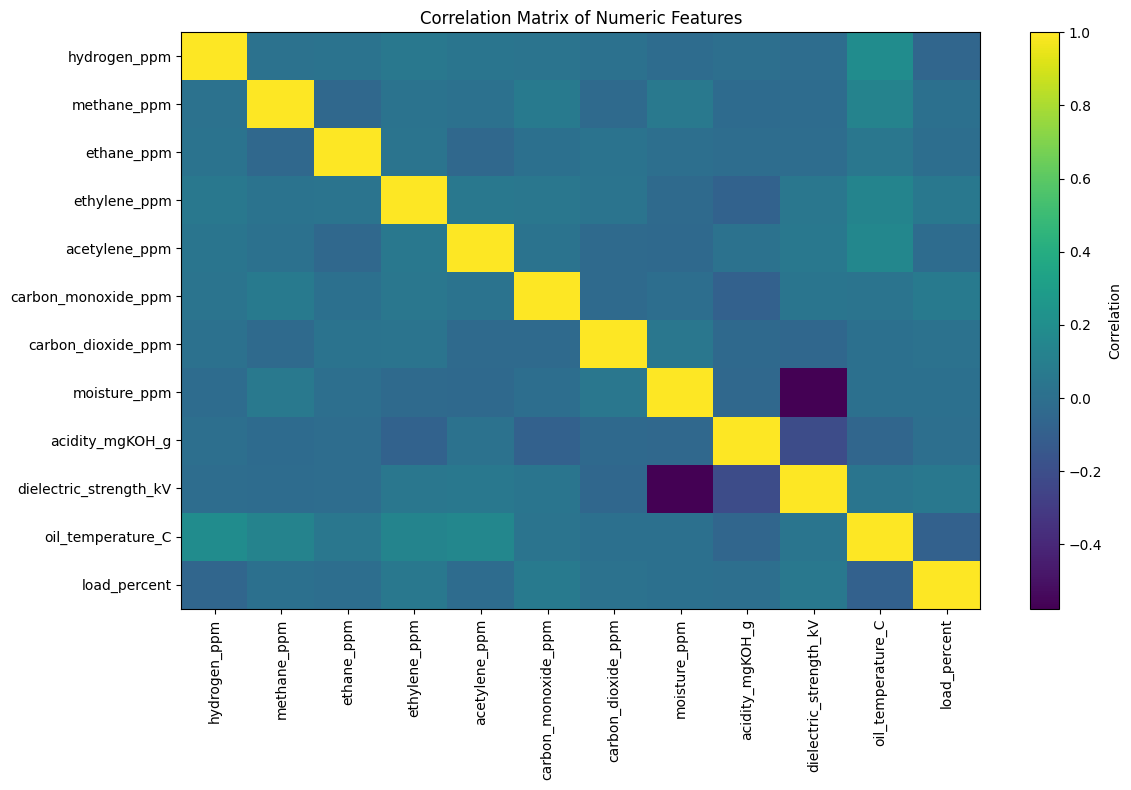

In [ ]:
import matplotlib.pyplot as plt

print('Condition counts:')
display(df['oil_condition'].value_counts().rename_axis('Condition').to_frame('Count'))

df['oil_condition'].value_counts().plot(kind='bar')
plt.title('Transformer Oil Condition Distribution')
plt.xlabel('Oil Condition')
plt.ylabel('Number of Samples')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

numeric_df = df.select_dtypes(include='number')
numeric_df.hist(figsize=(15, 10), bins=20)
plt.suptitle('Distribution of Numeric Measurements')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
plt.imshow(numeric_df.corr(), aspect='auto')
plt.colorbar(label='Correlation')
plt.xticks(range(len(numeric_df.columns)), numeric_df.columns, rotation=90)
plt.yticks(range(len(numeric_df.columns)), numeric_df.columns)
plt.title('Correlation Matrix of Numeric Features')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

target = 'oil_condition'
drop_cols = [target]
if 'transformer_id' in df.columns:
    drop_cols.append('transformer_id')

X = df.drop(columns=drop_cols).select_dtypes(include='number')
y = df[target].astype(str)

if y.nunique() < 2:
    raise ValueError('The target must contain at least two condition classes.')

# Removed stratify=y because the 'Critical' class has only 1 sample
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, shuffle=True
)

model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight='balanced'
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f'Test accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%')
print('\nClassification report:\n')
print(classification_report(y_test, y_pred, zero_division=0))

Test accuracy: 95.00%

Classification report:

              precision    recall  f1-score   support

      Normal       0.95      0.99      0.97       102
     Warning       0.93      0.72      0.81        18

    accuracy                           0.95       120
   macro avg       0.94      0.86      0.89       120
weighted avg       0.95      0.95      0.95       120



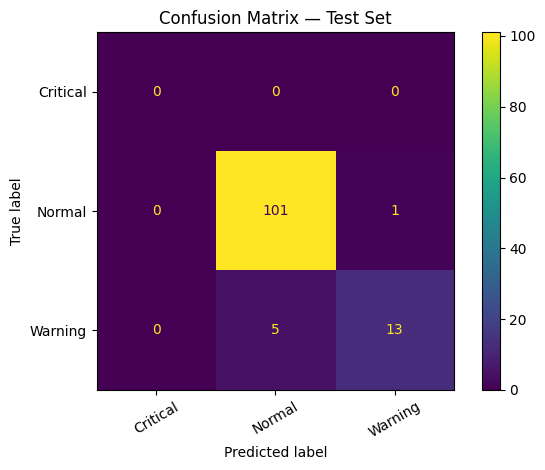

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(values_format='d', xticks_rotation=30)
plt.title('Confusion Matrix — Test Set')
plt.tight_layout()
plt.show()

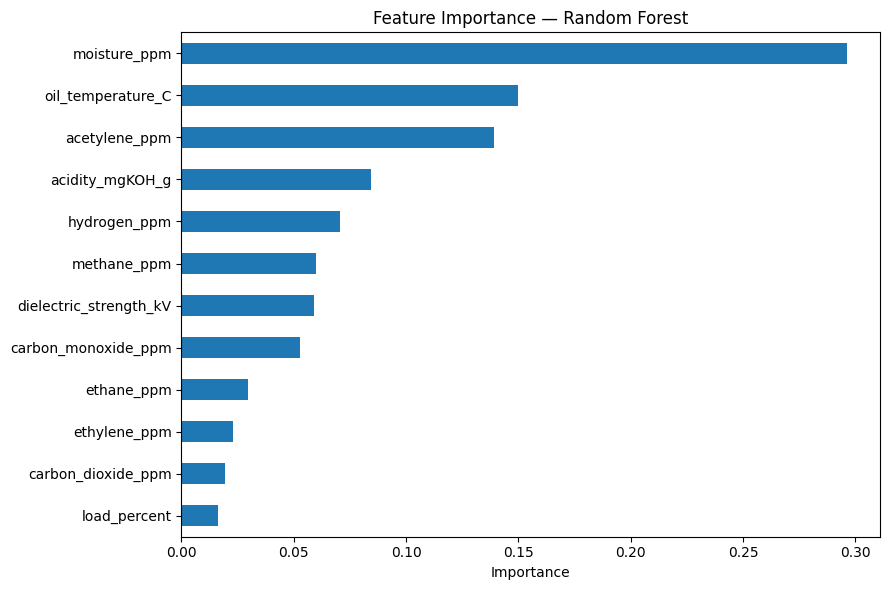

,Importance
moisture_ppm,0.296179
oil_temperature_C,0.149827
acetylene_ppm,0.138960
acidity_mgKOH_g,0.084589
hydrogen_ppm,0.070643
methane_ppm,0.059990
dielectric_strength_kV,0.058797
carbon_monoxide_ppm,0.052738
ethane_ppm,0.029817
ethylene_ppm,0.023052


In [ ]:
rf = model.named_steps['classifier']
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.plot(kind='barh', figsize=(9, 6))
plt.title('Feature Importance — Random Forest')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()
display(importance.sort_values(ascending=False).rename('Importance').to_frame())

In [ ]:
# Start with a real example row from the dataset, then change values as needed.
sample = X.iloc[[0]].copy()
sample.loc[:, 'hydrogen_ppm'] = 100
sample.loc[:, 'methane_ppm'] = 80
sample.loc[:, 'ethane_ppm'] = 35
sample.loc[:, 'ethylene_ppm'] = 180
sample.loc[:, 'acetylene_ppm'] = 25
sample.loc[:, 'carbon_monoxide_ppm'] = 60
sample.loc[:, 'carbon_dioxide_ppm'] = 500
sample.loc[:, 'moisture_ppm'] = 55
sample.loc[:, 'acidity_mgKOH_g'] = 0.35
sample.loc[:, 'dielectric_strength_kV'] = 30
sample.loc[:, 'oil_temperature_C'] = 100
sample.loc[:, 'load_percent'] = 90

predicted_condition = model.predict(sample)[0]
print('Predicted oil condition:', predicted_condition)

if hasattr(model.named_steps['classifier'], 'predict_proba'):
    probabilities = model.predict_proba(sample)[0]
    prob_df = pd.DataFrame({'Condition': model.classes_, 'Model score': probabilities})
    display(prob_df.sort_values('Model score', ascending=False))

print('Reminder: predictions from this synthetic demo dataset are not validated for real transformer operation.')

Predicted oil condition: Warning


,Condition,Model score
2,Warning,0.605
1,Normal,0.315
0,Critical,0.080


Reminder: predictions from this synthetic demo dataset are not validated for real transformer operation.


In [ ]:
import joblib

joblib.dump(model, 'transformer_oil_condition_model.joblib')
predictions = X_test.copy()
predictions['actual_condition'] = y_test.values
predictions['predicted_condition'] = y_pred
predictions.to_csv('transformer_oil_predictions.csv', index=False)

print('Saved model and predictions.')
from google.colab import files
files.download('transformer_oil_condition_model.joblib')
files.download('transformer_oil_predictions.csv')

Saved model and predictions.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np
import pandas as pd

controls = {}
for col in X.columns:
    lo = float(X[col].quantile(0.01))
    hi = float(X[col].quantile(0.99))
    val = float(X[col].median())
    if not np.isfinite(lo) or not np.isfinite(hi) or lo >= hi:
        lo, hi = float(X[col].min()), float(X[col].max())
    controls[col] = widgets.FloatSlider(
        value=val, min=lo, max=hi, step=max((hi-lo)/100, 0.001),
        description=col[:18], continuous_update=False,
        layout=widgets.Layout(width='95%'), style={'description_width': 'initial'}
    )

predict_button = widgets.Button(description='Predict Oil Condition', button_style='primary')
result = widgets.Output()

def predict_from_controls(_):
    with result:
        clear_output()
        row = pd.DataFrame([{col: widget.value for col, widget in controls.items()}])
        prediction = model.predict(row)[0]
        print('Predicted oil condition:', prediction)
        if hasattr(model.named_steps['classifier'], 'predict_proba'):
            probs = model.predict_proba(row)[0]
            display(pd.DataFrame({'Condition': model.classes_, 'Model score': probs})
                    .sort_values('Model score', ascending=False))
        print('Demonstration only: validate with real laboratory/field data before any use.')

predict_button.on_click(predict_from_controls)
display(widgets.VBox(list(controls.values()) + [predict_button, result]))